Bayesian estimation for $Y=\theta X+\epsilon$ with one observation $(x=1,y=2)$
(Victor Z and Jaron T, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $\theta\sim\mathcal{N}(\bar{\theta},\Sigma_\theta)$ | `theta_bar`, `Sigma_theta` | prior (0, 1) |
| $y\sim\mathcal{N}(\theta x,\sigma^2)$ | `sigma2` | likelihood noise variance (1) |
| $\log f(\theta)$, $\log f(y\mid\theta)$, $\log f(\theta\mid y)$ | `log_f_theta`, `log_f_y_theta`, `log_f_theta_y` | log prior, log likelihood, log posterior (up to a constant) |

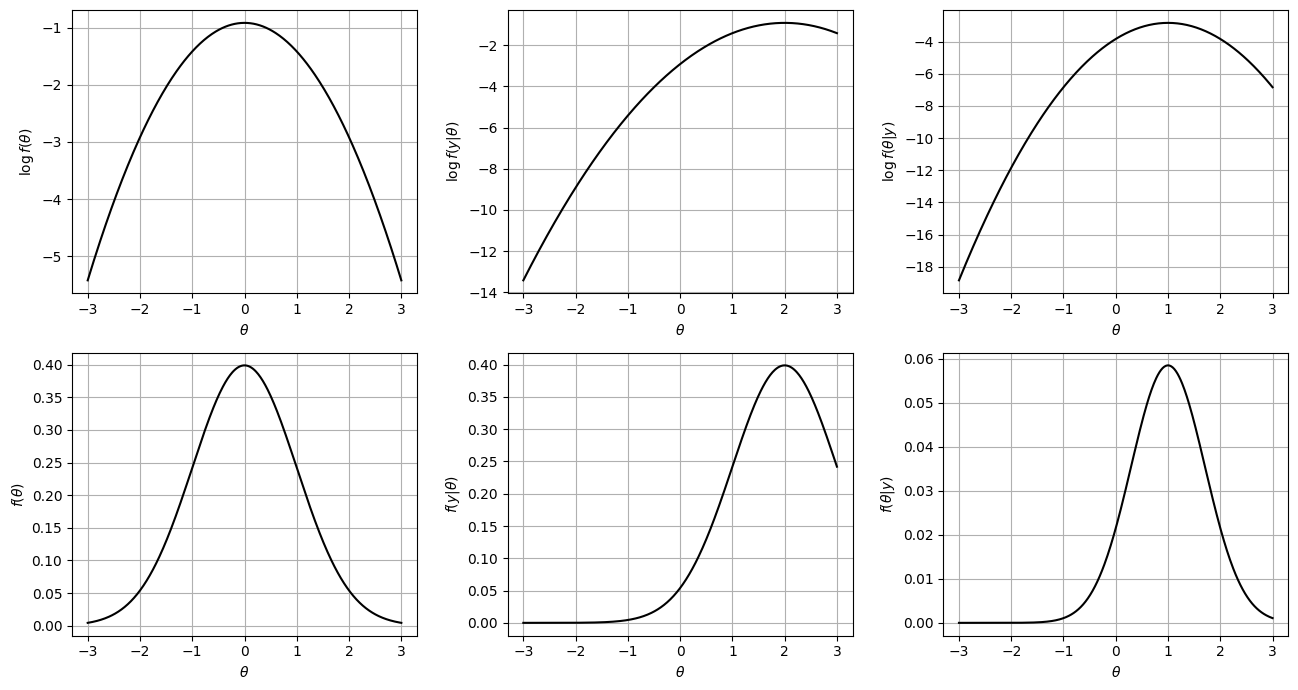

prior              is maximized at theta = -0.01
likelihood (MLE)   is maximized at theta = 1.99
posterior (Bayes)  is maximized at theta = 1.00


In [1]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(-3, 3, 400)
theta_bar, Sigma_theta = 0.0, 1.0
x, y, sigma2 = 1.0, 2.0, 1.0

log_f_theta = -0.5*np.log(2*np.pi*Sigma_theta) - (theta - theta_bar)**2 / (2*Sigma_theta)
log_f_y_theta = -0.5*np.log(2*np.pi*sigma2) - (y - theta*x)**2 / (2*sigma2)
log_f_theta_y = log_f_y_theta + log_f_theta          # Bayes: f(theta|y) ∝ f(y|theta) f(theta)

fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for k, (vals, label) in enumerate(((log_f_theta, r'f(\theta)'), (log_f_y_theta, r'f(y|\theta)'),
                                   (log_f_theta_y, r'f(\theta|y)'))):
    axs[0, k].plot(theta, vals, 'k', linewidth=1.5)
    axs[0, k].set_ylabel(rf'$\log {label}$')
    axs[1, k].plot(theta, np.exp(vals), 'k', linewidth=1.5)
    axs[1, k].set_ylabel(rf'${label}$')
    for ax in axs[:, k]:
        ax.set_xlabel(r'$\theta$')
        ax.grid(True)
plt.tight_layout()
plt.show()

for vals, name in ((log_f_theta, 'prior'), (log_f_y_theta, 'likelihood (MLE)'), (log_f_theta_y, 'posterior (Bayes)')):
    print(f"{name:18s} is maximized at theta = {theta[np.argmax(vals)]:.2f}")